# WavTokenizer Code

In [2]:
import warnings
warnings.simplefilter("ignore", UserWarning)
import sys
import os

sys.path.append(os.path.join(os.getcwd(), "WavTokenizer"))

import torchaudio
import torch
from encoder.utils import convert_audio # type: ignore
from decoder.pretrained import WavTokenizer # type: ignore

/home/enzo/vincent/wavtokenizer_test/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device=torch.device('cpu')
print(device)

config_path = "./WavTokenizer/configs/wavtokenizer_smalldata_frame40_3s_nq1_code4096_dim512_kmeans200_attn.yaml"
model_path = "./WavTokenizer/WavTokenizer_small_600_24k_4096.ckpt"

wavtokenizer = WavTokenizer.from_pretrained0802(config_path, model_path)
wavtokenizer = wavtokenizer.to(device)

cpu


/home/enzo/vincent/wavtokenizer_test/.venv/lib/python3.12/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


In [3]:
def wavtokenizer_from_raw_audio(tokenizer, audio_path, audio_outpath):
    wav, sr = torchaudio.load(audio_path)
    wav = convert_audio(wav, sr, 24000, 1) 
    bandwidth_id = torch.tensor([0])
    wav=wav.to(device)
    features, discrete_code = tokenizer.encode_infer(wav, bandwidth_id=bandwidth_id)
    audio_out = tokenizer.decode(features, bandwidth_id=bandwidth_id) 
    torchaudio.save(audio_outpath, audio_out, sample_rate=24000, encoding='PCM_S', bits_per_sample=16)
    return audio_out, features, discrete_code

def wavtokenizer_get_token(tokenizer, audio_path):
    wav, sr = torchaudio.load(audio_path)
    wav = convert_audio(wav, sr, 24000, 1)
    bandwidth_id = torch.tensor([0])
    wav=wav.to(device)
    _,audio_tokens= tokenizer.encode_infer(wav, bandwidth_id=bandwidth_id)
    return audio_tokens

def wavtokenizer_from_token(tokenizer, tokens, audio_outpath):
    features = tokenizer.codes_to_features(tokens)
    bandwidth_id = torch.tensor([0])  
    audio_out = tokenizer.decode(features, bandwidth_id=bandwidth_id)
    torchaudio.save(audio_outpath, audio_out, sample_rate=24000, encoding='PCM_S', bits_per_sample=16)
    return audio_out

## WavTokenizer examples

In [8]:
# reconstruct audio from raw wav
audio_path = "data/trump_en.wav"
audio_outpath = "result/test1.wav"
print(torchaudio.info(audio_path))

wav, sr = torchaudio.load(audio_path)
print(wav.shape)
wav = torchaudio.functional.resample(wav, sr, 24000, 1) 
print(wav.shape)
bandwidth_id = torch.tensor([0])
wav=wav.to(device)
features,discrete_code = wavtokenizer.encode_infer(wav, bandwidth_id=bandwidth_id)
audio_out = wavtokenizer.decode(features, bandwidth_id=bandwidth_id) 
torchaudio.save(audio_outpath, audio_out, sample_rate=24000, encoding='PCM_S', bits_per_sample=16)
print(torchaudio.info(audio_outpath))

AudioMetaData(sample_rate=16000, num_frames=238080, num_channels=1, bits_per_sample=16, encoding=PCM_S)
torch.Size([1, 238080])
torch.Size([1, 357120])
AudioMetaData(sample_rate=24000, num_frames=357600, num_channels=1, bits_per_sample=16, encoding=PCM_S)


In [16]:
wav.shape

torch.Size([1, 357120])

In [9]:
wav, sr = torchaudio.load(audio_outpath)
wav.shape

torch.Size([1, 357600])

In [6]:
# generating discrete codecs
wav, sr = torchaudio.load(audio_path)
wav = convert_audio(wav, sr, 24000, 1)
bandwidth_id = torch.tensor([0])
wav=wav.to(device)
_,audio_tokens= wavtokenizer.encode_infer(wav, bandwidth_id=bandwidth_id)
print(audio_tokens)
print(audio_tokens.shape)

tensor([[[ 827, 1923,  308,  719, 2035, 2763, 1690, 1489, 1690,  847, 2035,
           847, 2035,  370,  222, 2763, 1690, 2763, 1690, 2485,  222, 3879,
            59, 1420,  609,  980, 1615, 2212,  149,  258,  926,  907, 1619,
          1423, 2134, 1698, 1573, 1365, 1565, 2688,  564, 2198,   24,  140,
           979, 1198, 1433,  483, 1469, 1479, 1003, 1389, 1141, 1709, 1981,
           881, 1711,  382,  543, 1736,  821, 1428, 2027,   58,  538,  478,
          2163,  928,  820, 3733,  124,  255,  732, 2075, 2604,  612, 2589,
          3737, 1979,  537, 3078, 2421, 1075,  928,  203, 1979,  654,  759,
           596, 1262,  235, 1982,  681, 1223, 2140, 2527,  239, 3360,  868,
           796, 1184,  128, 1054, 2780,  862,  718, 1138, 1545, 3563, 1916,
           312,  457, 1318,  431,  943,  746, 1473,  636, 1802, 1999,  556,
           221, 1089, 1274,  400, 1489,  222,  847, 2126,  847,  807,  536,
          1275, 3993, 2283, 3310,   82, 1628,  776,  778, 1700, 3098,  776,
           3

In [7]:
# audio reconstructing through codecs
audio_outpath = "result/test2.wav"

features = wavtokenizer.codes_to_features(audio_tokens)
bandwidth_id = torch.tensor([0])  
audio_out_ = wavtokenizer.decode(features, bandwidth_id=bandwidth_id)
torchaudio.save(audio_outpath, audio_out_, sample_rate=24000, encoding='PCM_S', bits_per_sample=16)

In [8]:
torch.sum(audio_out - audio_out_)

tensor(0.)

# Test

In [9]:
import matplotlib.pyplot as plt

In [10]:
config_path_40 = "./WavTokenizer/configs/wavtokenizer_smalldata_frame40_3s_nq1_code4096_dim512_kmeans200_attn.yaml"
model_path_40 = "./WavTokenizer/WavTokenizer_small_600_24k_4096.ckpt"

wavtokenizer_40 = WavTokenizer.from_pretrained0802(config_path_40, model_path_40)
wavtokenizer_40 = wavtokenizer_40.to(device)

config_path_75 = "./WavTokenizer/configs/wavtokenizer_smalldata_frame75_3s_nq1_code4096_dim512_kmeans200_attn.yaml"
model_path_75 = "./WavTokenizer/WavTokenizer_small_320_24k_4096.ckpt"

wavtokenizer_75 = WavTokenizer.from_pretrained0802(config_path_75, model_path_75)
wavtokenizer_75 = wavtokenizer_75.to(device)

/home/enzo/vincent/wavtokenizer_test/.venv/lib/python3.12/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


In [5]:
def plot_waveform(waveform, sample_rate):
    waveform = waveform.numpy()

    num_channels, num_frames = waveform.shape
    time_axis = torch.arange(0, num_frames) / sample_rate

    figure, axes = plt.subplots(num_channels, 1)
    if num_channels == 1:
        axes = [axes]
    for c in range(num_channels):
        axes[c].plot(time_axis, waveform[c], linewidth=1)
        axes[c].grid(True)
        if num_channels > 1:
            axes[c].set_ylabel(f"Channel {c+1}")
        axes[c].set_xlabel("time")
        axes[c].set_ylabel("amplitude")
    figure.suptitle("waveform")
    plt.show(block=False)

def plot_specgram(waveform, sample_rate, title="Spectrogram"):
    waveform = waveform.numpy()

    num_channels, num_frames = waveform.shape

    figure, axes = plt.subplots(num_channels, 1)
    if num_channels == 1:
        axes = [axes]
    for c in range(num_channels):
        axes[c].specgram(waveform[c], Fs=sample_rate)
        if num_channels > 1:
            axes[c].set_ylabel(f"Channel {c+1}")
        axes[c].set_xlabel("time")
        axes[c].set_ylabel("frequency")
    figure.suptitle(title)
    plt.show(block=False)

## Spoken audio

In [4]:
audio_path1 = "data/7850_73752_000003_000012.wav"
metadata1 = torchaudio.info(audio_path1)
print(metadata1)

wav1, sr1 = torchaudio.load(audio_path1)

plot_waveform(wav1, sr1)
plot_specgram(wav1, sr1)

AudioMetaData(sample_rate=24000, num_frames=75600, num_channels=1, bits_per_sample=16, encoding=PCM_S)


NameError: name 'plot_waveform' is not defined

tensor([[[1936,  977,  409,  711,  629, 2335, 1969, 3623,  160, 1473, 1451,
            69,  346, 2006, 1654,  189, 2565, 3654, 1384, 2758, 1845,  426,
          1275,  495, 1208, 1733, 2781, 1152, 2383, 2262, 1087,  233,  518,
           491, 2805,  455,  908,  960,   65, 2738, 2639,  164, 3348, 1338,
           538, 3596,  198, 1935, 1045, 1785,  353, 2279, 2249,   72,  364,
          2140, 2283, 1839, 1370, 2052,  611, 1152,  379,   12, 1104, 1843,
            54, 1994, 2847,  380, 2756, 2883,  224, 3392,  457, 2064, 2734,
          3679, 1469,  233, 3335, 1244, 2493,  423, 2819, 2390, 2163,  302,
          1554, 1657, 2708,  456, 1332,  100, 1328,  526,  966, 1119,  758,
          1644, 1646,  850,   65, 1714,  295, 1121, 1583, 1406,  361, 1446,
          1435, 2381,   44, 2012,  704, 2053, 3062, 3118, 3106, 1320, 2446,
          2308,  853, 1332, 1347, 1812]]])
torch.Size([1, 1, 126])
AudioMetaData(sample_rate=24000, num_frames=75600, num_channels=1, bits_per_sample=16, encoding=P

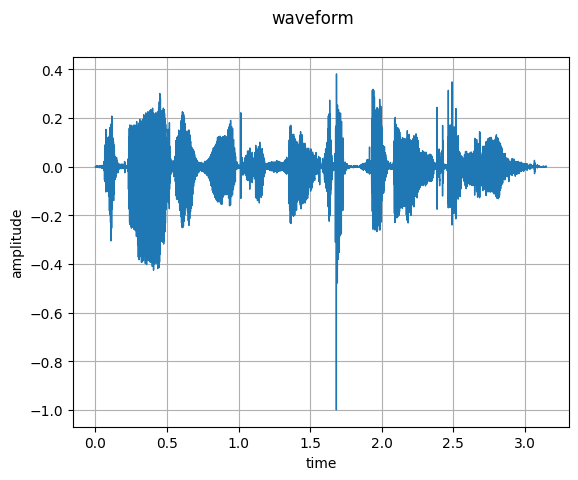

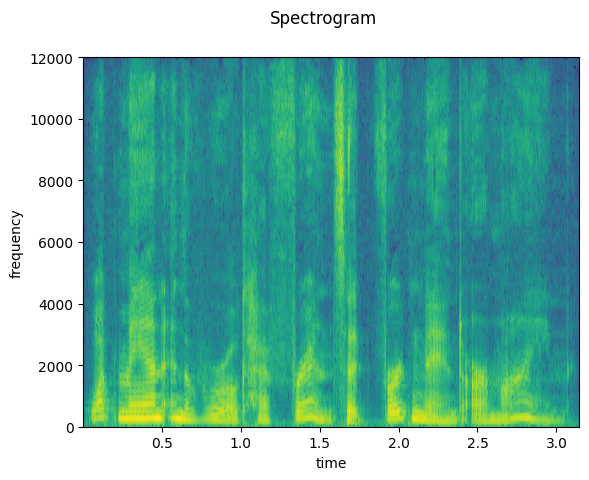

In [13]:
audio_outpath_recons = "result/test_recons_40.wav"

wav_recons, sr_recons = torchaudio.load(audio_path1)
wav_recons = convert_audio(wav_recons, sr_recons, 24000, 1) 
bandwidth_id = torch.tensor([0])
wav_recons=wav_recons.to(device)
features, audio_tokens = wavtokenizer_40.encode_infer(wav_recons, bandwidth_id=bandwidth_id)
audio_out = wavtokenizer_40.decode(features, bandwidth_id=bandwidth_id) 
torchaudio.save(audio_outpath_recons, audio_out, sample_rate=24000, encoding='PCM_S', bits_per_sample=16)

print(audio_tokens)
print(audio_tokens.shape)

metadata = torchaudio.info(audio_outpath_recons)
print(metadata)

wav_recons, sr_recons = torchaudio.load(audio_outpath_recons)

plot_waveform(wav_recons, sr_recons)
plot_specgram(wav_recons, sr_recons)

In [14]:
torch.sort(audio_tokens[0][0])

torch.return_types.sort(
values=tensor([  12,   44,   54,   65,   65,   69,   72,  100,  160,  164,  189,  198,
         224,  233,  233,  295,  302,  346,  353,  361,  364,  379,  380,  409,
         423,  426,  455,  456,  457,  491,  495,  518,  526,  538,  611,  629,
         704,  711,  758,  850,  853,  908,  960,  966,  977, 1045, 1087, 1104,
        1119, 1121, 1152, 1152, 1208, 1244, 1275, 1320, 1328, 1332, 1332, 1338,
        1347, 1370, 1384, 1406, 1435, 1446, 1451, 1469, 1473, 1554, 1583, 1644,
        1646, 1654, 1657, 1714, 1733, 1785, 1812, 1839, 1843, 1845, 1935, 1936,
        1969, 1994, 2006, 2012, 2052, 2053, 2064, 2140, 2163, 2249, 2262, 2279,
        2283, 2308, 2335, 2381, 2383, 2390, 2446, 2493, 2565, 2639, 2708, 2734,
        2738, 2756, 2758, 2781, 2805, 2819, 2847, 2883, 3062, 3106, 3118, 3335,
        3348, 3392, 3596, 3623, 3654, 3679]),
indices=tensor([ 63, 112,  66,  38, 102,  11,  53,  93,   8,  41,  15,  46,  72,  79,
         31, 104,  87,  12,  50, 108

In [15]:
print(features[0][:,38]-features[0][:,102])

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 

tensor([[[1936,  977,  409,  711,  629, 2335, 1969, 3623,  160, 1473, 1451,
            69,  346, 2006, 1654,  189, 2565, 3654, 1384, 2758, 1845,  426,
          1275,  495, 1208, 1733, 2781, 1152, 2383, 2262, 1087,  233,  518,
           491, 2805,  455,  908,  960,   65, 2738]]])
torch.Size([1, 1, 40])
AudioMetaData(sample_rate=24000, num_frames=24000, num_channels=1, bits_per_sample=16, encoding=PCM_S)


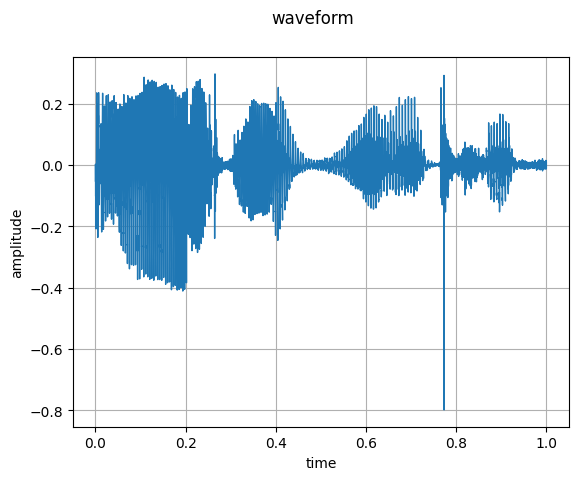

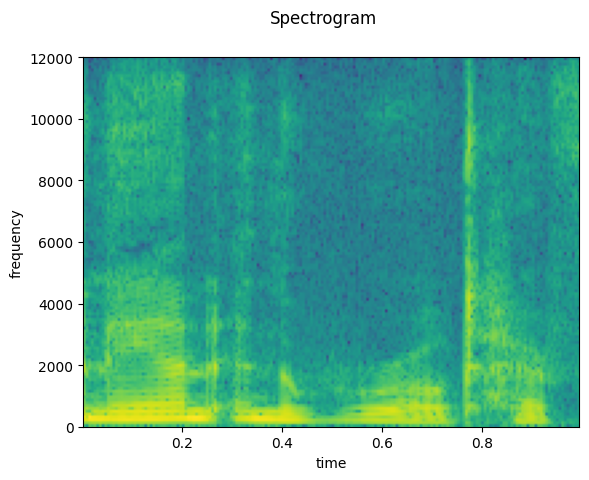

In [16]:
audio_outpath_recons = "result/test_recons_40_part.wav"

audio_out = wavtokenizer_40.decode(features[:,:,10:50], bandwidth_id=bandwidth_id) 
torchaudio.save(audio_outpath_recons, audio_out, sample_rate=24000, encoding='PCM_S', bits_per_sample=16)

print(audio_tokens[:,:,0:40])
print(audio_tokens[:,:,0:40].shape)

metadata = torchaudio.info(audio_outpath_recons)
print(metadata)

wav_recons, sr_recons = torchaudio.load(audio_outpath_recons)

plot_waveform(wav_recons, sr_recons)
plot_specgram(wav_recons, sr_recons)

tensor([[[1821, 1219, 2781, 1319,  104,  968, 2382, 1066, 1360, 2035, 1516,
          2123, 2603, 2833, 3812,  421,  436, 3389,  371, 1808, 3821, 2470,
          2162,  624, 2369, 4055, 1487, 2767, 3349, 1863, 1285,  881, 3679,
          1545, 3935, 1593, 1010,  116, 1568, 2185,  804,  717, 2883, 3709,
          2684,  436,  563,   72, 2172, 1439, 2448,  720, 3598,  104, 2930,
          3008, 3533,  585, 2348,  308,  261, 2789, 1271, 2450,  308, 3583,
          3709, 1655, 1812, 2938,  367, 2576, 3003,   27, 2365, 3567,  365,
          3786, 1204, 1072, 3530, 3349, 2598, 3730, 1815, 1157, 1317, 2502,
          2312, 1590, 1137, 3203, 2935,  703, 3983, 3464, 3103, 3533, 3873,
          1296,  279, 1973, 3383,  957, 3623, 3716, 3492,  639, 2017, 1369,
          2442, 3792, 1862, 1838, 1547, 3108, 2301,  872, 1602, 2330, 2404,
          1038, 1938, 1433, 3825, 3932, 1648, 3800, 3732,  158, 3507, 2224,
          3008, 2810, 1049, 3125, 2060,  599, 3986, 1590,  473, 3880, 3464,
           9

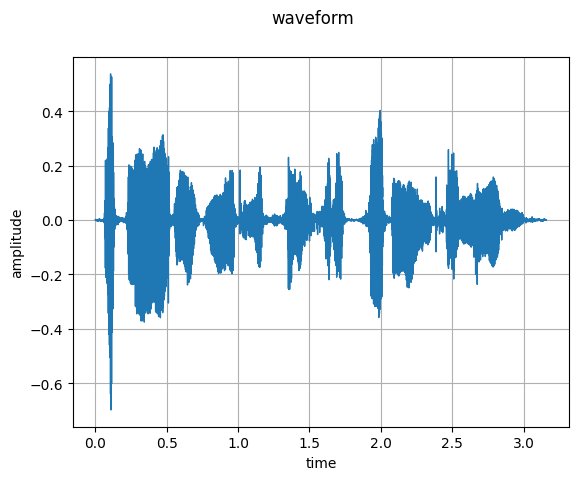

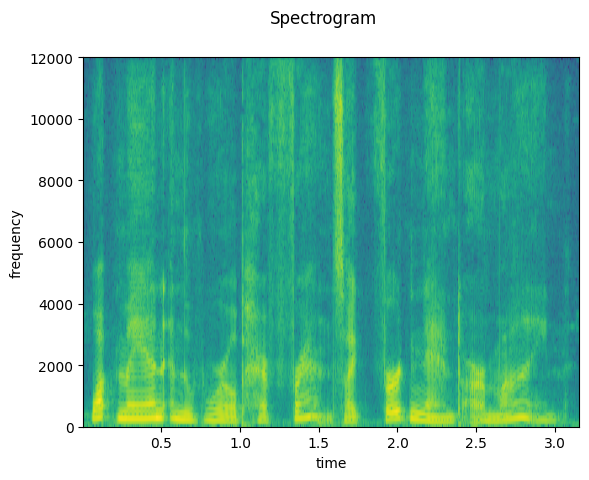

In [17]:
audio_outpath_recons = "result/test_recons_75.wav"

wav_recons, sr_recons = torchaudio.load(audio_path1)
wav_recons = convert_audio(wav_recons, sr_recons, 24000, 1) 
bandwidth_id = torch.tensor([0])
wav_recons=wav_recons.to(device)
features, audio_tokens = wavtokenizer_75.encode_infer(wav_recons, bandwidth_id=bandwidth_id)
audio_out = wavtokenizer_75.decode(features, bandwidth_id=bandwidth_id) 
torchaudio.save(audio_outpath_recons, audio_out, sample_rate=24000, encoding='PCM_S', bits_per_sample=16)

print(audio_tokens)
print(audio_tokens.shape)

metadata = torchaudio.info(audio_outpath_recons)
print(metadata)

wav_recons, sr_recons = torchaudio.load(audio_outpath_recons)

plot_waveform(wav_recons, sr_recons)
plot_specgram(wav_recons, sr_recons)

## Constant audio

AudioMetaData(sample_rate=24000, num_frames=48000, num_channels=1, bits_per_sample=16, encoding=PCM_S)


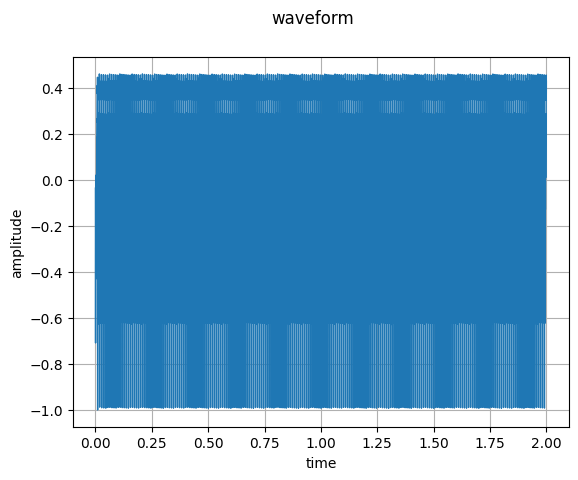

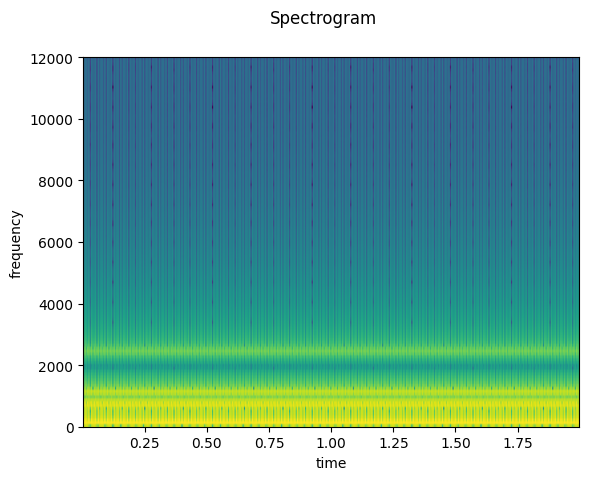

In [18]:
audio_path2 = "data/a.wav"
metadata2 = torchaudio.info(audio_path2)
print(metadata2)

wav2, sr2 = torchaudio.load(audio_path2)

plot_waveform(wav2, sr2)
plot_specgram(wav2, sr2)

tensor([[[1555, 1500,    6, 2458, 1436,  328,    6, 2458, 1436, 1101,    6,
          2330, 1436, 1101,    6, 2330, 1436, 1101,    6, 2330, 1436, 1101,
             6, 2330, 1436, 1101,    6, 2330, 1436, 1101,    6, 2330, 1436,
          1101,    6, 2330, 1436, 1101,    6, 2330, 1436, 1101,    6, 2330,
          1436, 1101,    6, 2330, 1436, 1101,    6, 2330, 1436, 1101,    6,
          2330, 1436, 1101,    6, 2330, 1436, 1101,    6, 2330, 1436, 1101,
             6, 2330, 1436, 1101,    6, 2330, 1436, 1101,    6, 2330, 1436,
          1101,    6, 2330]]])
torch.Size([1, 1, 80])
AudioMetaData(sample_rate=24000, num_frames=48000, num_channels=1, bits_per_sample=16, encoding=PCM_S)


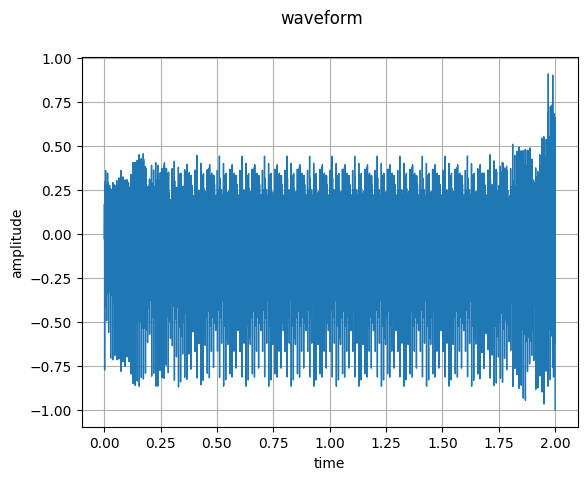

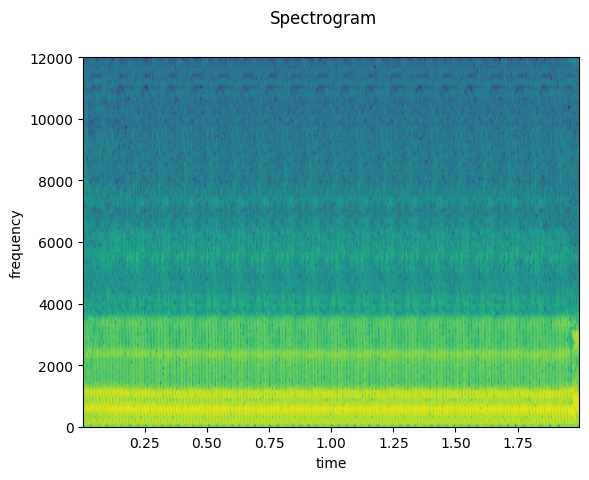

In [19]:
audio_outpath_recons = "result/a_recons_40.wav"

wav_recons, sr_recons = torchaudio.load(audio_path2)
wav_recons = convert_audio(wav_recons, sr_recons, 24000, 1) 
bandwidth_id = torch.tensor([0])
wav_recons=wav_recons.to(device)
features, audio_tokens = wavtokenizer_40.encode_infer(wav_recons, bandwidth_id=bandwidth_id)
audio_out = wavtokenizer_40.decode(features, bandwidth_id=bandwidth_id) 
torchaudio.save(audio_outpath_recons, audio_out, sample_rate=24000, encoding='PCM_S', bits_per_sample=16)

print(audio_tokens)
print(audio_tokens.shape)

metadata = torchaudio.info(audio_outpath_recons)
print(metadata)

wav_recons, sr_recons = torchaudio.load(audio_outpath_recons)

plot_waveform(wav_recons, sr_recons)
plot_specgram(wav_recons, sr_recons)

torch.return_types.sort(
values=tensor([   6,    6,    6,    6,    6,    6,    6,    6,    6,    6,    6,    6,
           6,    6,    6,    6,    6,    6,    6,    6,  328, 1101, 1101, 1101,
        1101, 1101, 1101, 1101, 1101, 1101, 1101, 1101, 1101, 1101, 1101, 1101,
        1101, 1101, 1101, 1436, 1436, 1436, 1436, 1436, 1436, 1436, 1436, 1436,
        1436, 1436, 1436, 1436, 1436, 1436, 1436, 1436, 1436, 1436, 1500, 1555,
        2330, 2330, 2330, 2330, 2330, 2330, 2330, 2330, 2330, 2330, 2330, 2330,
        2330, 2330, 2330, 2330, 2330, 2330, 2458, 2458]),
indices=tensor([78, 58, 54, 50, 62, 46, 42, 38, 66, 34, 30, 26, 70, 22, 18,  6, 14,  2,
        74, 10,  5, 45, 41, 65, 37, 49, 77,  9, 33, 61, 29, 53, 69, 25, 13, 21,
        57, 17, 73, 52, 60, 48, 56,  4, 16, 44, 64, 40, 76, 36,  8, 32, 68, 28,
        24, 12, 20, 72,  1,  0, 27, 79, 75, 11, 15, 19, 71, 23, 59, 31, 67, 35,
        39, 43, 63, 47, 51, 55,  7,  3]))


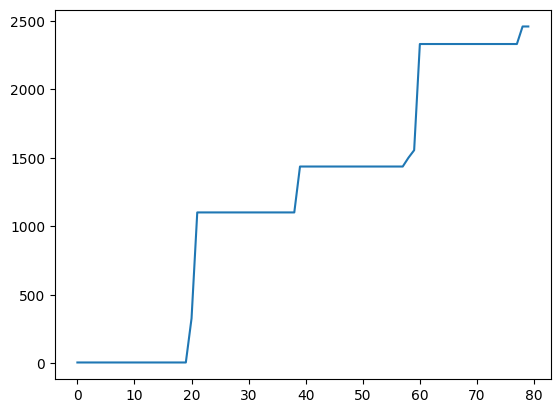

In [20]:
print(torch.sort(audio_tokens[0][0]))
plt.plot(torch.sort(audio_tokens[0][0])[0])

tensor([[[3054, 1475, 2304, 2513, 2854,  307,  968, 3024, 3440, 3343, 1069,
           122, 1057, 1683, 1475, 1747, 1486,  441, 3938, 2068, 3162, 3054,
           116, 3440, 3447, 1069,  122, 1057, 1683, 1475, 1747, 1486,  441,
          3938, 2068, 3162, 3054,  116, 3440, 3447, 1069,  122, 1057, 1683,
          1475, 1747, 1486,  441, 3938, 2068, 3162, 3054,  116, 3440, 3447,
          1069,  122, 1057, 1683, 1475, 1747, 1486,  441, 3938, 2068, 3162,
          3054,  116, 3440, 3447, 1069,  122, 1057, 1683, 2195, 1747, 1486,
           441, 3938, 2068, 3162, 3054, 3078, 2444, 3447, 1069,  122, 1057,
          2690, 2195, 1747, 1486,  441, 3938, 2068, 3162, 3054,  116, 3440,
          3447, 1069,  122, 1057, 1683, 2195, 1747, 1486,  441, 3938, 2068,
          3162, 3054,  116, 3440, 3447, 1069,  122, 1057, 1683, 1475, 1747,
          1486,  441, 3938, 2068, 3162, 3054,  116, 3440, 3447, 1069,  122,
          1057, 1683, 2195, 1747, 1486,  441, 3938, 2068, 3162, 3054,  116,
          34

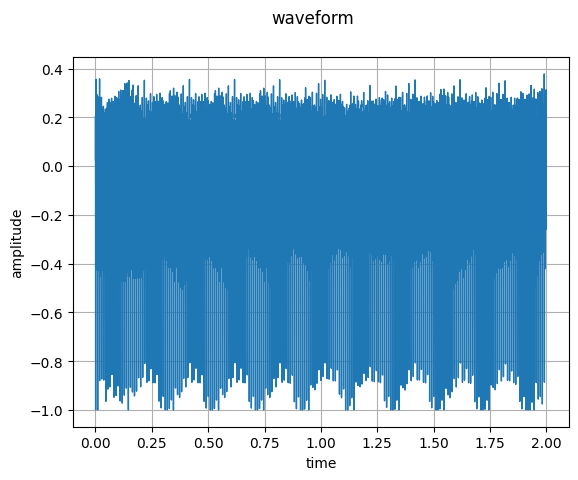

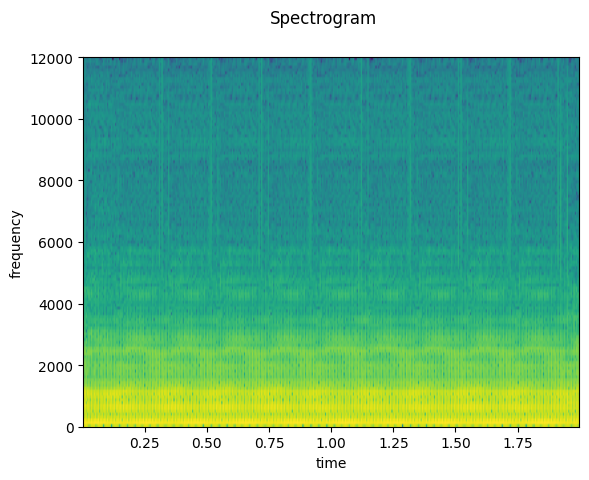

In [21]:
audio_outpath_recons = "result/a_recons_75.wav"

wav_recons, sr_recons = torchaudio.load(audio_path2)
wav_recons = convert_audio(wav_recons, sr_recons, 24000, 1) 
bandwidth_id = torch.tensor([0])
wav_recons=wav_recons.to(device)
features, audio_tokens = wavtokenizer_75.encode_infer(wav_recons, bandwidth_id=bandwidth_id)
audio_out = wavtokenizer_75.decode(features, bandwidth_id=bandwidth_id) 
torchaudio.save(audio_outpath_recons, audio_out, sample_rate=24000, encoding='PCM_S', bits_per_sample=16)

print(audio_tokens)
print(audio_tokens.shape)

metadata = torchaudio.info(audio_outpath_recons)
print(metadata)

wav_recons, sr_recons = torchaudio.load(audio_outpath_recons)

plot_waveform(wav_recons, sr_recons)
plot_specgram(wav_recons, sr_recons)

torch.return_types.sort(
values=tensor([  67,  116,  116,  116,  116,  116,  116,  116,  116,  122,  122,  122,
         122,  122,  122,  122,  122,  122,  122,  307,  441,  441,  441,  441,
         441,  441,  441,  441,  441,  602,  723,  968, 1057, 1057, 1057, 1057,
        1057, 1057, 1057, 1057, 1057, 1069, 1069, 1069, 1069, 1069, 1069, 1069,
        1069, 1069, 1069, 1475, 1475, 1475, 1475, 1475, 1475, 1486, 1486, 1486,
        1486, 1486, 1486, 1486, 1486, 1486, 1683, 1683, 1683, 1683, 1683, 1683,
        1683, 1683, 1747, 1747, 1747, 1747, 1747, 1747, 1747, 1747, 1747, 2068,
        2068, 2068, 2068, 2068, 2068, 2068, 2068, 2068, 2195, 2195, 2195, 2195,
        2304, 2444, 2513, 2690, 2854, 3024, 3054, 3054, 3054, 3054, 3054, 3054,
        3054, 3054, 3054, 3054, 3078, 3162, 3162, 3162, 3162, 3162, 3162, 3162,
        3162, 3162, 3343, 3440, 3440, 3440, 3440, 3440, 3440, 3440, 3440, 3440,
        3447, 3447, 3447, 3447, 3447, 3447, 3447, 3447, 3447, 3938, 3938, 3938,
        

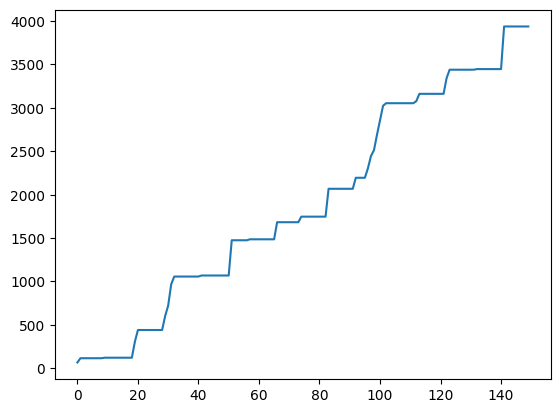

In [22]:
print(torch.sort(audio_tokens[0][0]))
plt.plot(torch.sort(audio_tokens[0][0])[0])

### Codebook Inspection

AudioMetaData(sample_rate=24000, num_frames=2457600, num_channels=1, bits_per_sample=16, encoding=PCM_S)


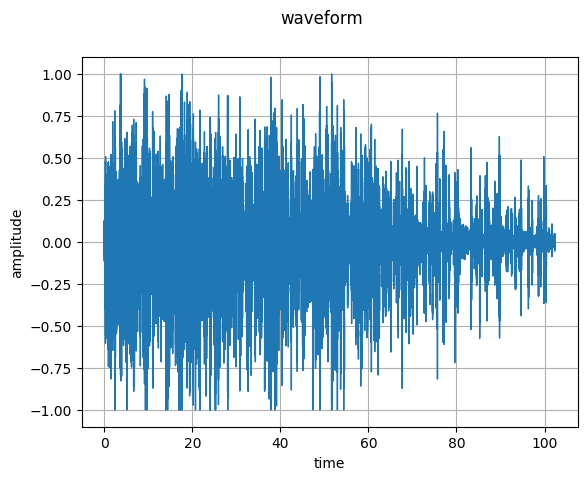

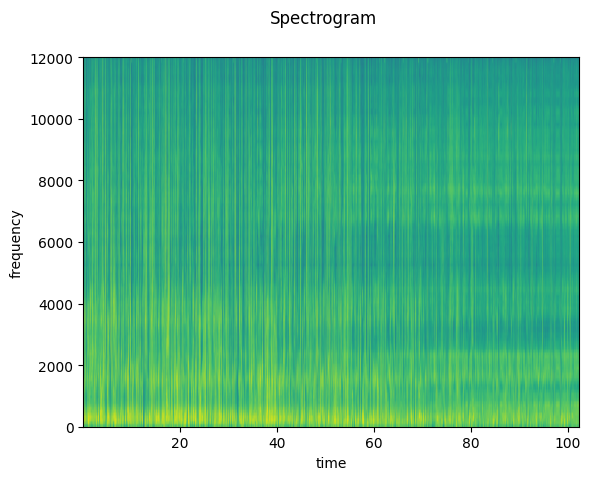

In [23]:
audio_tokens = torch.arange(0,2**12).unsqueeze(0).unsqueeze(0)
features = wavtokenizer_40.codes_to_features(audio_tokens)
bandwidth_id = torch.tensor([0])
audio_out = wavtokenizer_40.decode(features, bandwidth_id=bandwidth_id)
torchaudio.save("result/all_tokens_40.wav", audio_out, sample_rate=24000, encoding='PCM_S', bits_per_sample=16)

metadata = torchaudio.info("result/all_tokens_40.wav")
print(metadata)

wav_all_40, sr_all_40 = torchaudio.load("result/all_tokens_40.wav")

plot_waveform(wav_all_40, sr_all_40)
plot_specgram(wav_all_40, sr_all_40)

AudioMetaData(sample_rate=24000, num_frames=1310720, num_channels=1, bits_per_sample=16, encoding=PCM_S)


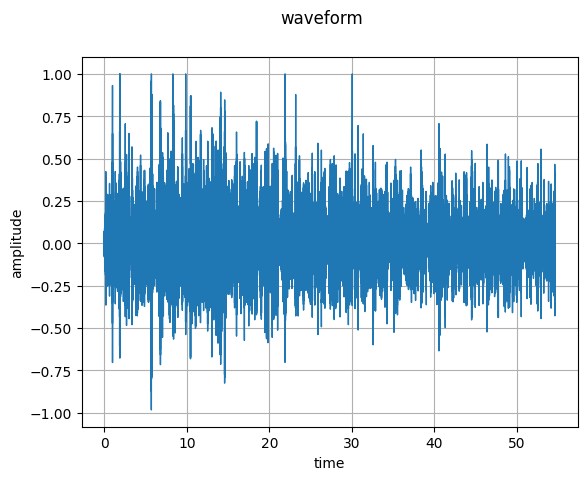

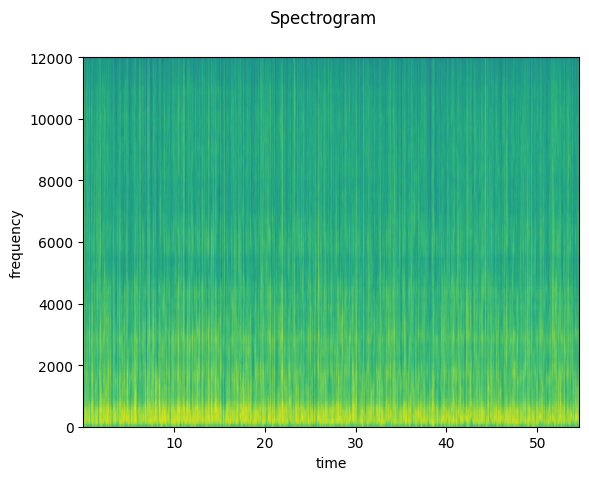

In [24]:
audio_tokens = torch.arange(0,2**12).unsqueeze(0).unsqueeze(0)
features = wavtokenizer_75.codes_to_features(audio_tokens)
bandwidth_id = torch.tensor([0])
audio_out = wavtokenizer_75.decode(features, bandwidth_id=bandwidth_id)
torchaudio.save("result/all_tokens_75.wav", audio_out, sample_rate=24000, encoding='PCM_S', bits_per_sample=16)

metadata = torchaudio.info("result/all_tokens_75.wav")
print(metadata)

wav_all_75, sr_all_75 = torchaudio.load("result/all_tokens_75.wav")

plot_waveform(wav_all_75, sr_all_75)
plot_specgram(wav_all_75, sr_all_75)

AudioMetaData(sample_rate=24000, num_frames=72000, num_channels=1, bits_per_sample=16, encoding=PCM_S)


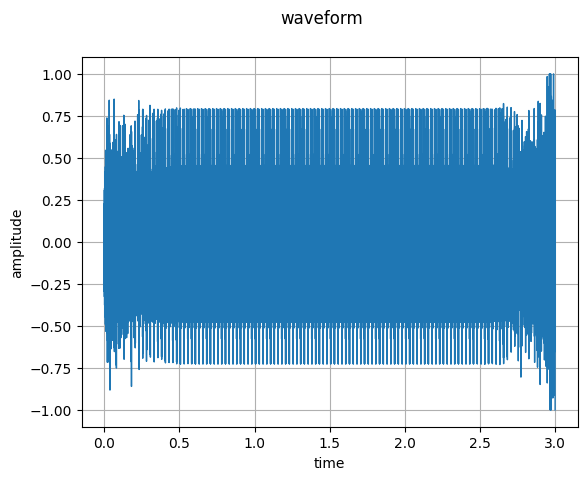

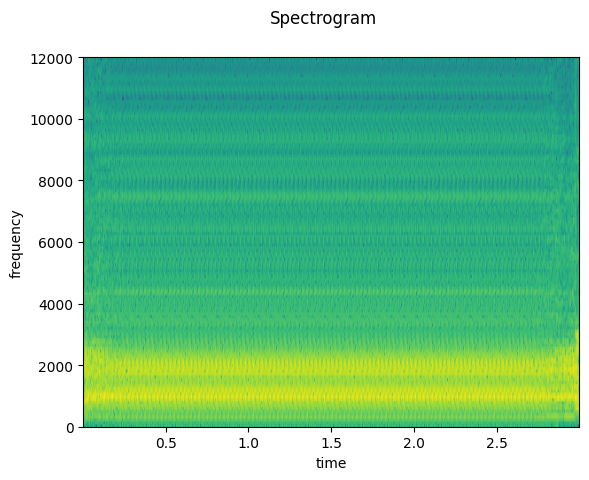

In [25]:
audio_tokens = torch.unsqueeze(torch.ones(120, dtype=int) * 2330, 0).unsqueeze(0)
features = wavtokenizer_40.codes_to_features(audio_tokens)
bandwidth_id = torch.tensor([0])
audio_out = wavtokenizer_40.decode(features, bandwidth_id=bandwidth_id)
torchaudio.save("result/test.wav", audio_out, sample_rate=24000, encoding='PCM_S', bits_per_sample=16)

metadata = torchaudio.info("result/test.wav")
print(metadata)

wav_test, sr_test = torchaudio.load("result/test.wav")

plot_waveform(wav_test, sr_test)
plot_specgram(wav_test, sr_test)

# Metrics

In [26]:
from torchaudio.pipelines import SQUIM_OBJECTIVE, SQUIM_SUBJECTIVE
from torchmetrics.audio.nisqa import NonIntrusiveSpeechQualityAssessment

In [ ]:
def get_obj_metrics(audio_path):
    model = SQUIM_OBJECTIVE.get_model()
    wav, _ = torchaudio.load(audio_path)
    stoi, pesq, si_sdr = model(wav[0:1,:])
    print("STOI:", {stoi[0]})
    print("PESQ:", {pesq[0]})
    print("SI-SDR:", {si_sdr[0]})
    return stoi, pesq, si_sdr

def get_sub_metrics(audio_path, audio_path_ref):
    model = SQUIM_SUBJECTIVE.get_model()
    wav, _ = torchaudio.load(audio_path)
    wav_ref, _ = torchaudio.load(audio_path_ref)
    mos= model(wav[0:1,:], wav_ref[0:1,:])
    print("MOS:", {mos[0]})
    return mos

In [28]:
audio_path = "data/7850_73752_000003_000012.wav"
audio_path_recons40 = "result/test_recons_40.wav"
audio_path_recons75 = "result/test_recons_75.wav"

print("Metrics for original sound :")
_,_,_ = get_obj_metrics(audio_path)
_ = get_sub_metrics(audio_path, audio_path)
print("\n")

print("Metrics for compression with wavtokenizer 40tokens/s :")
_,_,_ = get_obj_metrics(audio_path_recons40)
_ = get_sub_metrics(audio_path_recons40, audio_path)
print("\n")

print("Metrics for compression with wavtokenizer 75tokens/s :")
_,_,_ = get_obj_metrics(audio_path_recons75)
_ = get_sub_metrics(audio_path_recons75, audio_path)
print("\n")

Metrics for original sound :
STOI: {tensor(0.9879, grad_fn=<SelectBackward0>)}
PESQ: {tensor(3.5008, grad_fn=<SelectBackward0>)}
SI-SDR: {tensor(26.5465, grad_fn=<SelectBackward0>)}
MOS: {tensor(4.5164, grad_fn=<SelectBackward0>)}


Metrics for compression with wavtokenizer 40tokens/s :
STOI: {tensor(0.9730, grad_fn=<SelectBackward0>)}
PESQ: {tensor(2.6735, grad_fn=<SelectBackward0>)}
SI-SDR: {tensor(10.6315, grad_fn=<SelectBackward0>)}
MOS: {tensor(3.9605, grad_fn=<SelectBackward0>)}


Metrics for compression with wavtokenizer 75tokens/s :
STOI: {tensor(0.9902, grad_fn=<SelectBackward0>)}
PESQ: {tensor(3.4985, grad_fn=<SelectBackward0>)}
SI-SDR: {tensor(22.4154, grad_fn=<SelectBackward0>)}
MOS: {tensor(4.4352, grad_fn=<SelectBackward0>)}




tensor([4.6455, 4.1067, 4.4354, 4.2425, 4.4678])
tensor([3.2512, 3.5204, 3.5426, 3.8090, 4.0451])
tensor([4.0108, 3.6552, 4.1056, 3.9699, 4.1563])


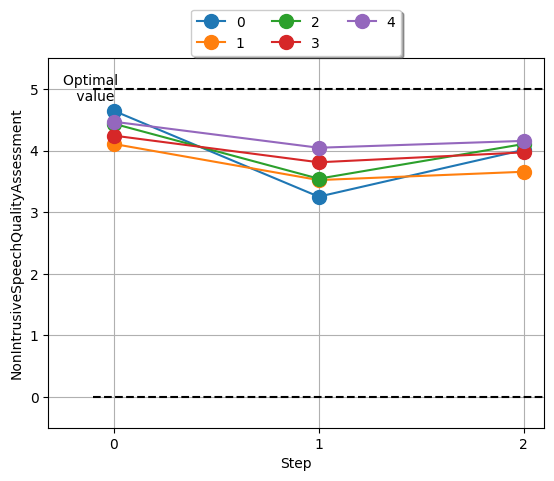

In [29]:
wav, _ = torchaudio.load(audio_path)
wav_recons_40, _, _ = wavtokenizer_from_raw_audio(wavtokenizer_40, audio_path, audio_path_recons40)
wav_recons_75, _, _ = wavtokenizer_from_raw_audio(wavtokenizer_75, audio_path, audio_path_recons75)

nisqa = NonIntrusiveSpeechQualityAssessment(24000)
print(nisqa(wav))
print(nisqa(wav_recons_40))
print(nisqa(wav_recons_75))

values=[nisqa(wav), nisqa(wav_recons_40), nisqa(wav_recons_75)]
fix_, ax_ = nisqa.plot(values)